 This is mnist dataset... so the thing is we will train this dataset on the 6000 instead of 70000 data because we didnt learn working on gpu yet so we will use cpu 
thats why we will take 6k data as it will take a alot of time on cpu


### *now start ANN -> ARtificial neural network*

#STRUCTURE OF OUR NEURRAL NETWORK
- INPUT LAYER 784 NODE
- HIDDEN LAYER 


*   1ST 128 NODES WITH RELU
*   2ND 64 WITH RELU
*   3RD OUTPUT SOFTMAX AS MULTIPLE CLASSIFICATION PROBLEM




# WORKFLOW
1. DATALOADER
2. TRAINING LOOP
3. EVALUATION  


# Bismillah

In [1]:
import pandas as pd
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, Dataset
from sklearn.model_selection import train_test_split
import seaborn as sns
import torch.optim as optim
import matplotlib.pyplot as plt


In [2]:
#set random seed
torch.manual_seed(42)

In [34]:
df=pd.read_csv("mnist.csv")

In [4]:
df

,label,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,2,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,6,0,0,0,0,0,0,0,5,0,...,0,0,0,30,43,0,0,0,0,0
3,0,0,0,0,1,2,0,0,0,0,...,3,0,0,0,0,1,0,0,0,0
4,3,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
59995,9,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
59996,1,0,0,0,0,0,0,0,0,0,...,73,0,0,0,0,0,0,0,0,0
59997,8,0,0,0,0,0,0,0,0,0,...,160,162,163,135,94,0,0,0,0,0
59998,8,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0


In [5]:
df["label"].value_counts()

label
2    6000
9    6000
6    6000
0    6000
3    6000
4    6000
5    6000
8    6000
7    6000
1    6000
Name: count, dtype: int64

In [35]:
df=df.groupby("label").sample(n=1000, random_state=42)

In [36]:
df = df.sample(frac=1).reset_index(drop=True)

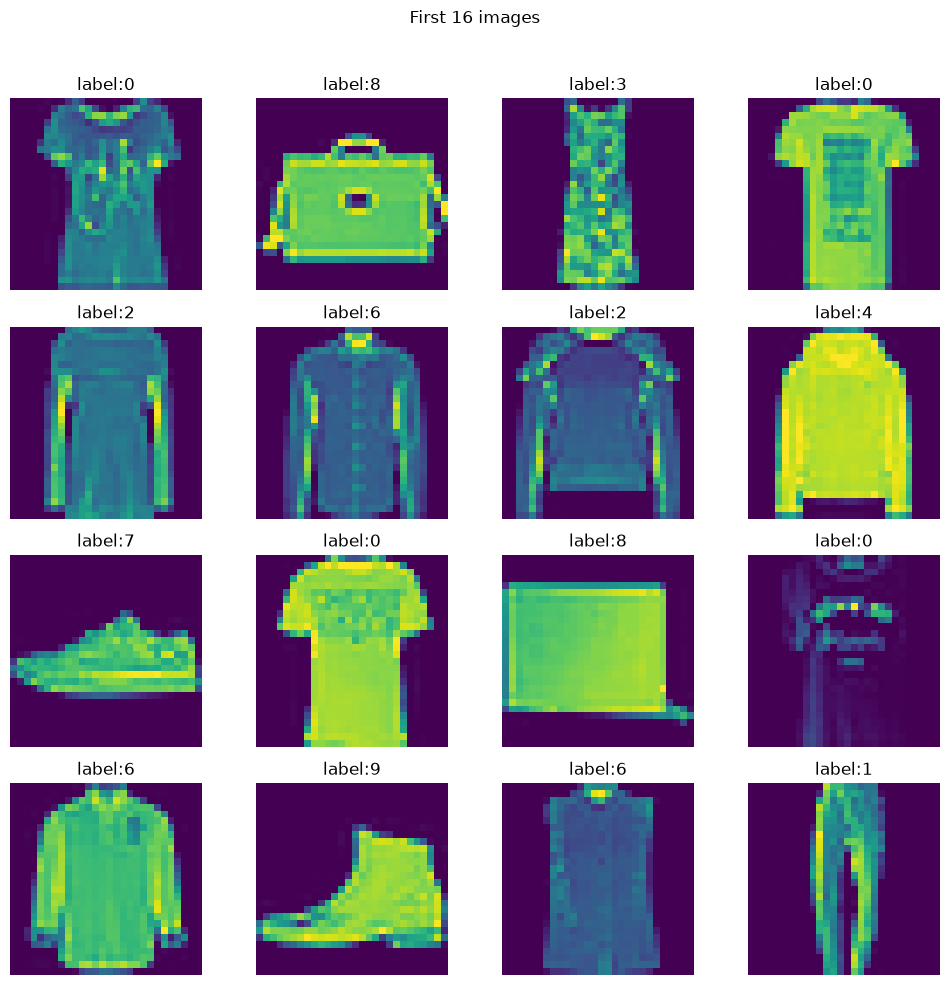

In [37]:
fig,axes=plt.subplots(4,4,figsize=(10,10))
fig.suptitle("First 16 images")

for i,ax in enumerate (axes.flat):
    img=df.iloc[i,1:].values.reshape(28,28)
    ax.imshow(img)
    ax.axis('off')
    ax.set_title(f"label:{df.iloc[i,0]}")
plt.tight_layout(rect=[0,0,1,0.96])
plt.show()

In [38]:
x=df.drop(columns='label')
y=df['label']

In [10]:
x

,pixel1,pixel2,pixel3,pixel4,pixel5,pixel6,pixel7,pixel8,pixel9,pixel10,...,pixel775,pixel776,pixel777,pixel778,pixel779,pixel780,pixel781,pixel782,pixel783,pixel784
0,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,0,0,0,0,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,0,0,0,0,0,0,0,0,0,26,...,26,33,0,0,0,0,0,0,0,0
9996,0,0,0,0,0,0,0,1,0,0,...,0,0,105,161,118,0,0,0,0,0
9997,0,0,0,0,0,0,0,0,0,77,...,0,0,0,128,155,86,0,0,0,0
9998,0,0,0,0,0,0,0,0,0,69,...,144,171,165,0,0,1,0,0,0,0


In [11]:
y

0       5
1       5
2       7
3       9
4       1
       ..
9995    6
9996    4
9997    2
9998    0
9999    4
Name: label, Length: 10000, dtype: int64

In [39]:
x_train,x_test,y_train,y_test=train_test_split(
    x,y,shuffle=True,stratify=y,test_size=0.25
)

In [40]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(y_test.shape)

(7500, 784)
(7500,)
(2500, 784)
(2500,)


In [41]:
x_train=(x_train/255.0).to_numpy()
x_test=(x_test/255.0).to_numpy()

In [42]:
# custom class
class custom(Dataset):
    def __init__(self,feat,label):
        self.feat= torch.tensor(feat, dtype=torch.float32)
        self.label= torch.tensor(label, dtype=torch.long)
    def __len__(self):
        return len(self.feat)
    def __getitem__(self,index):
        return self.feat[index],self.label[index]

In [43]:
s1=custom(x_train,y_train)

In [44]:
len(s1)

7500

In [45]:
s1.__len__()

7500

In [51]:
train_data=custom(x_train,y_train)

In [47]:
import numpy as np

In [54]:
y_train = y_train.to_numpy(dtype=np.int64)
y_test = y_test.to_numpy(dtype=np.int64)


train_data = custom(x_train, y_train)
test_data = custom(x_test, y_test)

In [55]:
test_data=custom(x_test,y_test)

In [56]:
test_data.__len__()

2500

In [57]:
#create train and test loader
train_loader=DataLoader(
    train_data, batch_size=32)
test_loader= DataLoader(
    test_data, batch_size=32)

In [58]:
# Define neural network class
class my_nn(nn.Module):

    def __init__(self, num_feat):
        super().__init__()

        self.model = nn.Sequential(
            nn.Linear(num_feat, 128),
            nn.ReLU(),

            nn.Linear(128, 64),
            nn.ReLU(),

            nn.Linear(64, 10),
            
        )

    def forward(self, x):
        return self.model(x)
        
        

In [59]:
epochs=20
lr=0.176


In [60]:
model=my_nn(x_train.shape[1])
crit=nn.CrossEntropyLoss()
opt=optim.SGD(model.parameters(), lr=lr)

In [61]:
len(train_loader)

235

In [62]:
# training loop

for epoch in range(epochs):
    total_loss=0;
    for batch_features,batch_labels in train_loader:
        # print(batch_features,batch_labels)
        out=model(batch_features)
        loss=crit(out,batch_labels)
        opt.zero_grad()
        loss.backward()
        opt.step()
        total_loss=total_loss+loss.item()
    print(f"average loss | {total_loss/len(train_loader)}")
        
                
    

average loss | 1.0377669154963596
average loss | 0.6384101038600536
average loss | 0.5556477440798536
average loss | 0.5013313779647046
average loss | 0.462219007075467
average loss | 0.42788613446532414
average loss | 0.4016133600568518
average loss | 0.3769370801746845
average loss | 0.3581481276832997
average loss | 0.3397824152987054
average loss | 0.32485241698140793
average loss | 0.3161014913878542
average loss | 0.29418646625857403
average loss | 0.28246249217302244
average loss | 0.2673220960145935
average loss | 0.28229904044815834
average loss | 0.25655026716437745
average loss | 0.24974589672018874
average loss | 0.2351355247595843
average loss | 0.22234865775767793


In [63]:
#set model evaluation
model.eval()

my_nn(
  (model): Sequential(
    (0): Linear(in_features=784, out_features=128, bias=True)
    (1): ReLU()
    (2): Linear(in_features=128, out_features=64, bias=True)
    (3): ReLU()
    (4): Linear(in_features=64, out_features=10, bias=True)
  )
)

In [64]:
from sklearn.metrics import precision_score, recall_score, f1_score,accuracy_score

In [66]:
all_pred=[]
all_labels=[]
with torch.no_grad():
    for batch_features, batch_labels in test_loader:
        out=model(batch_features)
        pred=torch.max(out,1)[1]
        all_pred.extend(pred)
        all_labels.extend(batch_labels)
print(f"accuracy: {accuracy_score(all_labels,all_pred)}")
print(recall_score(
    all_labels, all_pred, average="macro", zero_division=0
))

print(f1_score(
    all_labels, all_pred, average="macro", zero_division=0
))

print(precision_score(
    all_labels, all_pred, average="macro", zero_division=0
))       

accuracy: 0.8388
0.8388
0.8387151844038188
0.842445000550011
